# Which New York City buildings face Local Law 97 fines?

Local Law 97 of 2019 sets a yearly limit on the greenhouse gas emissions of most buildings over 25,000 square feet in
New York City. From 2024 a building over its limit pays $268 for each tonne of CO2e over, every year. The limits
tighten in 2030.

The city publishes what each large building used in a year (the Local Law 84 energy and water disclosure), but not the
building's limit, its emissions as the law counts them, or where it is. This notebook works out, for calendar year 2024
(the first year of the law), each benchmarked property's emissions and limit for 2024 to 2029 and 2030 to 2034, and the
penalty it would pay if it used the same energy. The tables were made with the scripts described in the README; the
shapes in `data/geometry/` were made in [Plotlay](https://www.getplotlay.com).

The notebook reads only the files in `../data` and runs top to bottom in under a minute.

In [1]:
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

DATA = '../data'
pd.set_option('display.width', 160, 'display.max_columns', 20)
RED, INK, MUTED = '#cf3b26', '#1d4f91', '#5b6573'
PENALTY = 268  # US$ per tonne of CO2e over the limit (Admin Code 28-320.6, as DOB states it)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
p = pd.read_csv(f'{DATA}/tables/properties.csv', dtype={'property_id': str, 'cd': str, 'bbl': str})
f = pd.read_csv(f'{DATA}/tables/emissions_factors.csv')
k = pd.read_csv(f'{DATA}/tables/coefficients.csv')
print(len(p), 'properties kept;', p.pathway.value_counts().to_dict())

27270 properties kept; {'Article 320': 22797, 'City-owned': 1737, 'Tax-exempt housing': 1163, 'HDFC': 942, 'NYCHA': 237, 'State or federal': 224, 'House of worship': 170}


## 1. The rule: a limit from the floor area of each use

1 RCNY 103-14 gives an emissions factor in tonnes of CO2e per square foot for each Energy Star Portfolio Manager
property type, one table for 2024 to 2029 and another for 2030 to 2034. A building's limit is the sum of each use's
floor area times its factor (Equation 103-14.1). Here is the factor table, and the energy coefficients.

In [2]:
display(f.head(12))
display(k)

,espm_type,factor_2024_2029,factor_2030_2034,ll84_names,source
0,Adult Education,0.00758,0.003566,NaN,1 RCNY 103-14 (c)(3)(i) and (iii)
1,Ambulatory Surgical Center,0.01181,0.008981,NaN,1 RCNY 103-14 (c)(3)(i) and (iii)
2,Automobile Dealership,0.00675,0.002824,Vehicle Dealership,1 RCNY 103-14 (c)(3)(i) and (iii)
3,Bank Branch,0.00987,0.004036,NaN,1 RCNY 103-14 (c)(3)(i) and (iii)
4,Bowling Alley,0.00574,0.003104,NaN,1 RCNY 103-14 (c)(3)(i) and (iii)
5,College/University,0.00987,0.002100,NaN,1 RCNY 103-14 (c)(3)(i) and (iii)
6,Convenience Store without Gas Station,0.00675,0.003540,NaN,1 RCNY 103-14 (c)(3)(i) and (iii)
7,Courthouse,0.00426,0.001481,NaN,1 RCNY 103-14 (c)(3)(i) and (iii)
8,Data Center,0.02381,0.014791,NaN,1 RCNY 103-14 (c)(3)(i) and (iii)
9,Distribution Center,0.00574,0.000992,NaN,1 RCNY 103-14 (c)(3)(i) and (iii)


,ll84_column,unit,coefficient_2024_2029,coefficient_2030_2034,unit_out
0,electricity_use_grid_purchase_1,kWh,0.000289,0.000145,tCO2e per kWh
1,natural_gas_use_kbtu,kBtu,0.000053,0.000053,tCO2e per kBtu
2,fuel_oil_1_use_kbtu,kBtu,0.000073,0.000073,tCO2e per kBtu
3,fuel_oil_2_use_kbtu,kBtu,0.000074,0.000074,tCO2e per kBtu
4,fuel_oil_4_use_kbtu,kBtu,0.000075,0.000075,tCO2e per kBtu
5,fuel_oil_5_6_use_kbtu,kBtu,0.000076,0.000076,tCO2e per kBtu
6,diesel_2_use_kbtu,kBtu,0.000074,0.000074,tCO2e per kBtu
7,propane_use_kbtu,kBtu,0.000064,0.000064,tCO2e per kBtu
8,kerosene_use_kbtu,kBtu,0.000078,0.000078,tCO2e per kBtu
9,district_steam_use_kbtu,kBtu,0.000045,0.000043,tCO2e per kBtu


## 2. One building, by hand

Take the property with the largest floor area in the totals, and work its limit and emissions out from its uses and
its energy, the same way `properties.csv` was made.

In [3]:
fac = f.set_index('espm_type')
NO_FACTOR = {'Wastewater Treatment Plant', 'Drinking Water Treatment & Distribution', 'Energy/Power Station', 'Other - Utility', 'Electric Vehicle Charging Station', 'Heated Swimming Pool'}
def limit_of(uses, col):
    """uses: 'Office (165378.0), Parking (11941.0)' as LL84 lists them"""
    import re
    total = 0.0; area = 0.0; other = 0.0
    for name, g in re.findall(r'(.+?) \((N/A|[\d.]+)\)(?:, |$)', uses):
        g = float(g)
        if g == 0: continue
        if name in NO_FACTOR: continue          # a use the rule gives no factor (a power station): left out of the limit
        t = fac.index[fac.index == name]
        t = name if len(t) else (fac[fac.ll84_names.fillna('').str.split('; ').apply(lambda xs: name in xs)].index.tolist() or [None])[0]
        if t is None: other += g; continue      # plain "Other": the average factor of the property's other uses
        total += g * fac.loc[t, col]; area += g
    return total * (area + other) / area if area else np.nan

tot = p[(p.pathway == 'Article 320') & p.check.isna()]
one = tot.loc[tot.gfa_uses.idxmax()]
print(one.property_name, '|', one.list_of_all_property_use)
print('limit 2024-2029, recomputed:', round(limit_of(one.list_of_all_property_use, 'factor_2024_2029'), 1), ' table:', one.limit_2024)
print('limit 2030-2034, recomputed:', round(limit_of(one.list_of_all_property_use, 'factor_2030_2034'), 1), ' table:', one.limit_2030)
print('emissions 2024 (t):', one.emissions_2024, ' over:', one.over_2024, ' penalty:', one.penalty_2024)

Parkchester Full Campus (North + South) | Restaurant (8379.0), Multifamily Housing (12385937.0), Energy/Power Station (50000.0), Office (4453.0), Medical Office (9987.0), Bank Branch (20461.0), Courthouse (7516.0), Retail Store (213434.0), Mailing Center/Post Office (17077.0), Personal Services (Health/Beauty, Dry Cleaning, etc.) (15777.0), Vocational School (2614.0), Vehicle Repair Services (696.0), Pre-school/Daycare (2500.0), Other - Restaurant/Bar (788.0), Food Service (2101.0), Supermarket/Grocery Store (40405.0), Convenience Store without Gas Station (7321.0), Community Center and Social Meeting Hall (4500.0), Parking (210000.0), Fast Food Restaurant (9474.0), Fitness Center/Health Club/Gym (14350.0)
limit 2024-2029, recomputed: 88256.3  table: 88256.3
limit 2030-2034, recomputed: 42720.1  table: 42720.1
emissions 2024 (t): 66583.2  over: 0.0  penalty: 0.0


## 3. What is counted

Every record LL84 published for calendar 2024 is accounted for: kept and in the totals, kept but likely on another
compliance pathway (city-owned, NYCHA, HDFC, houses of worship, state or federal, tax-exempt housing), kept but failing
a data check, or left out with a reason (`excluded.csv`).

In [4]:
ex = pd.read_csv(f'{DATA}/tables/excluded.csv')
print(ex.why.value_counts().to_string())
print()
print(p.groupby(['pathway', p.check.fillna('passed')]).size().unstack(fill_value=0))

why
child_of_parent_in_data    9988
no_energy_reported         1291
implausible_site_eui        209
unoccupied                  208
not_existing                 44
only_other_use               30
uses_without_area            25
use_with_no_factor           22
no_floor_area                 3

check               emissions far from Portfolio Manager  passed  site EUI far from its type
pathway                                                                                     
Article 320                                           64   21753                         980
City-owned                                             3    1671                          63
HDFC                                                   1     910                          31
House of worship                                       1     159                          10
NYCHA                                                  0     225                          12
State or federal                                       0

## 4. The totals

The headline counts only properties on the standard pathway (Article 320) whose records pass the data checks.

In [5]:
def period(df, y):
    o = df[df[f'over_{y}'] > 0]
    return pd.Series({'properties': len(df), 'over': len(o), 'share over': len(o) / len(df), 'penalty a year (US$M)': o[f'penalty_{y}'].sum() / 1e6,
                      'tonnes over': o[f'over_{y}'].sum(), 'median penalty when over (US$)': o[f'penalty_{y}'].median()})
summary = pd.DataFrame({'2024 to 2029': period(tot, '2024'), '2030 to 2034': period(tot, '2030')})
display(summary.round(3))
# the penalty is the tonnes over times $268, nothing more
assert abs(tot.penalty_2024.sum() - (tot.over_2024 * PENALTY).sum()) < len(tot)

,2024 to 2029,2030 to 2034
properties,21753.000,21753.000
over,1830.000,13546.000
share over,0.084,0.623
penalty a year (US$M),58.574,532.831
tonnes over,218558.500,1988174.400
median penalty when over (US$),13598.500,17442.000


## 5. How much the total depends on what is counted

Put back the records that fail a data check, then every pathway. The headline is the first row.

In [6]:
rows = {'Article 320, data checks passed': tot, 'plus records failing a data check': p[p.pathway == 'Article 320'], 'plus every pathway': p}
display(pd.DataFrame({k: [v[v.over_2024 > 0].penalty_2024.sum() / 1e6, v[v.over_2030 > 0].penalty_2030.sum() / 1e6] for k, v in rows.items()},
                     index=['2024 to 2029 (US$M)', '2030 to 2034 (US$M)']).T.round(1))

,2024 to 2029 (US$M),2030 to 2034 (US$M)
"Article 320, data checks passed",58.6,532.8
plus records failing a data check,118.8,611.8
plus every pathway,265.0,1011.4


## 6. By kind of building and by borough

In [7]:
g = tot.groupby('primary_property_type').agg(n=('property_id', 'size'), over_2024=('over_2024', lambda s: (s > 0).mean()), over_2030=('over_2030', lambda s: (s > 0).mean()),
                                             penalty_2030_m=('penalty_2030', lambda s: s.sum() / 1e6)).sort_values('n', ascending=False).head(10)
display(g.round(3))
b = tot.groupby('borough').agg(n=('property_id', 'size'), penalty_2024_m=('penalty_2024', lambda s: s.sum() / 1e6), penalty_2030_m=('penalty_2030', lambda s: s.sum() / 1e6))
display(b.round(2))

,n,over_2024,over_2030,penalty_2030_m
primary_property_type,,,,
Multifamily Housing,15594,0.086,0.627,280.863
Office,2027,0.050,0.532,59.744
Hotel,630,0.081,0.557,25.147
K-12 School,498,0.074,0.715,8.164
Non-Refrigerated Warehouse,315,0.092,0.787,7.478
Mixed Use Property,259,0.116,0.591,15.568
Retail Store,252,0.123,0.718,7.285
Self-Storage Facility,240,0.000,0.525,1.771
Manufacturing/Industrial Plant,231,0.043,0.784,5.275


,n,penalty_2024_m,penalty_2030_m
borough,,,
Bronx,3486,11.30,85.35
Brooklyn,5384,6.22,75.32
Manhattan,8551,29.01,266.12
Queens,3858,9.92,91.26
Staten Island,302,1.81,11.13


## 7. On the map: community districts

Plotlay placed every property in the community district it stands in (by its PLUTO position) and added up the
penalties. Here the same is done with GeoPandas, and checked against the district Plotlay exported.

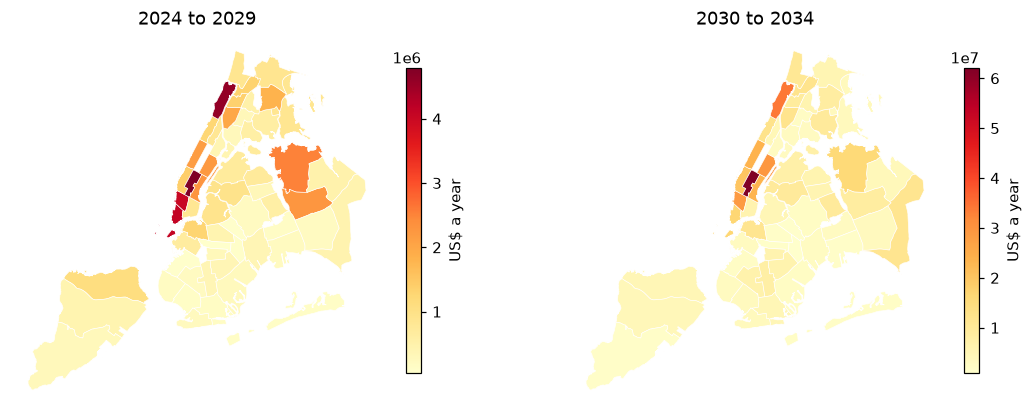

placed in a district by position: 21560 of 21574
Midtown (105), 2030 to 2034: US$ 62.1 M placed by position (as Plotlay places them); 63.0 M by the district PLUTO gives the lot


In [8]:
cd = gpd.read_file(f'{DATA}/geometry/community_districts.geojson')
pts = gpd.GeoDataFrame(tot, geometry=gpd.points_from_xy(tot.lng, tot.lat), crs=4326).dropna(subset=['lat'])
j = gpd.sjoin(pts, cd[['key', 'geometry']], predicate='within')
by = j.groupby('key').agg(penalty_2024=('penalty_2024', 'sum'), penalty_2030=('penalty_2030', 'sum'), share_over_2030=('over_2030', lambda s: (s > 0).mean()))
m = cd.merge(by, left_on='key', right_index=True, how='left')
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
for ax, col, title in zip(axs, ['penalty_2024', 'penalty_2030'], ['2024 to 2029', '2030 to 2034']):
    m.to_crs(32618).plot(ax=ax, column=col, cmap='YlOrRd', legend=True, edgecolor='white', linewidth=.4, legend_kwds={'shrink': .6, 'label': 'US$ a year'})
    ax.set_title(title); ax.set_axis_off()
plt.show()
print('placed in a district by position:', len(j), 'of', len(pts))
print('Midtown (105), 2030 to 2034: US$', round(by.loc['105', 'penalty_2030'] / 1e6, 1), 'M placed by position (as Plotlay places them);',
      round(tot[tot.cd == '105'].penalty_2030.sum() / 1e6, 1), 'M by the district PLUTO gives the lot')

## 8. Midtown, building by building

Every footprint of every benchmarked property in Manhattan Community District 5, keyed by its LL84 property id.

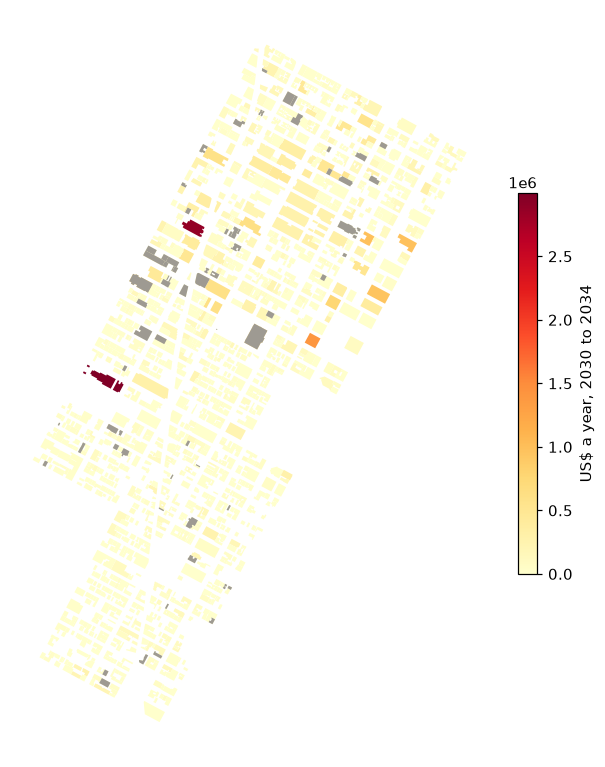

1431 properties with footprints (a property with several buildings is one shape of several parts); tallest roof 472.4 m


In [9]:
fp = gpd.read_file(f'{DATA}/geometry/midtown_buildings.geojson')
mt = pd.read_csv(f'{DATA}/tables/midtown_by_period.csv', dtype={'property_id': str})
v = mt[mt.period_label == '2030 to 2034'].set_index('property_id')
fp['penalty'] = fp['key'].map(v.penalty_usd); fp['status'] = fp['key'].map(v.status)
ax = fp.to_crs(32618).plot(column='penalty', cmap='YlOrRd', figsize=(7, 9), legend=True, legend_kwds={'shrink': .5, 'label': 'US$ a year, 2030 to 2034'}, missing_kwds={'color': '#bbb'})
fp[fp.status != 'In the totals'].to_crs(32618).plot(ax=ax, color='#9e9a92')
ax.set_axis_off(); plt.show()
print(fp['key'].nunique(), 'properties with footprints (a property with several buildings is one shape of several parts); tallest roof', fp.height_m.max(), 'm')

## Read it carefully

- **An estimate, not a bill.** The penalty is what a building would pay at $268 a tonne if its 2024 report stood as
  published. Owners can correct reports, use the 2024 to 2025 good faith provisions, buy renewable energy credits or
  apply for adjustments, none of which shows in open data.
- **2030 to 2034 assumes nothing changes.** It applies the 2030 limits and coefficients to calendar 2024 energy use.
  Buildings that cut use, or the grid getting cleaner beyond the rule's coefficient, lower it.
- **The pathway is a flag from PLUTO, not a fact.** Rent-regulated buildings (more than 35% of units) follow Article
  321 and cannot be told apart in open data, so some multifamily properties in the totals may not face these penalties.
- **Data checks.** A record whose site energy per square foot is more than three times, or under a quarter of, its
  property type's median, or whose emissions differ from Portfolio Manager's own by more than half, is kept out of the
  totals.